# Get specific files from parent folder based on site and method

In [7]:
"""
GET THE RIGHT FILES:
"""
from pathlib import Path

def find_csv_files(parent_dir, site_tag, method):
    """
    Search parent_dir for subfolders matching S2_{site_tag}* and return
    CSV files within them that start with {method} and contain {site_tag}.

    Parameters
    ----------
    parent_dir : str or Path — root directory to search
    site_tag   : str — e.g. "CC", "COR", "KW", "UB"
    method     : str — e.g. "STUMPF", "XGBRF"

    Returns
    -------
    list of Path objects
    """
    parent = Path(parent_dir)

    matching_folders = [
        f for f in parent.iterdir()
        if f.is_dir() and f.name.startswith(f"S2_{site_tag}_")
    ]

    csv_files = []
    for folder in matching_folders:
        for csv in folder.glob("*.csv"):
            if csv.name.startswith(method) and site_tag in csv.name:
                csv_files.append(csv)

    csv_files.sort()

    print(f"Found {len(matching_folders)} folders, {len(csv_files)} CSV files:")
    for f in csv_files:
        print(f)

    return csv_files

# Set up the Depth Dissagregate plot functions


In [8]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from matplotlib.patches import Patch
import sys


warnings.filterwarnings("ignore")


PALETTE = [  "#b2df8a", # light gren
           "#33a02c",  # dark green
           "#a6cee3", # dark blue
           "#1f78b4", # light blye
           "#F26A52", # orange
           "#F970FF", # pink
           "#F2DF52", # yellowish
           "#9D45BF" #  dark purple
]


MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*", "h", "<"]

# ── metrics ───────────────────────────────────────────────────────────────────

def _mae(true, pred):
    return np.mean(np.abs(pred - true))

def _rmse(true, pred):
    return np.sqrt(np.mean((pred - true) ** 2))

def _bias(true, pred):
    return np.mean(pred - true)

def _r2(true, pred):
    ss_res = np.sum((true - pred) ** 2)
    ss_tot = np.sum((true - np.mean(true)) ** 2)
    return 1 - ss_res / ss_tot if ss_tot > 0 else 1.0

# ── loader ────────────────────────────────────────────────────────────────────

def _load(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    if "True" in df.columns and "TRUE" not in df.columns:
        df = df.rename(columns={"True": "TRUE"})
    missing = {"TRUE", "Predicted"} - set(df.columns)
    if missing:
        raise ValueError(f"{path}: missing columns {missing}. Found: {list(df.columns)}")
    df = df.dropna(subset=["TRUE", "Predicted"])
    return df

# ── binning ───────────────────────────────────────────────────────────────────

def _make_bins(start=0, stop=20, width=2):
    edges  = np.arange(start, stop + width, width)
    labels = [f"{edges[i]:.0f}–{edges[i+1]:.0f}" for i in range(len(edges) - 1)]
    return edges, labels

def _bin_mae(df, edges, labels, metric_fn):
    """Bin by Predicted depth."""
    results = []
    for i in range(len(labels)):
        mask = (df["Predicted"] >= edges[i]) & (df["Predicted"] < edges[i + 1])
        sub  = df[mask]
        if len(sub) >= 2:
            results.append({"bin": labels[i], "mid": (edges[i] + edges[i + 1]) / 2,
                            "value": metric_fn(sub["TRUE"].values, sub["Predicted"].values), "n": len(sub)})
        else:
            results.append({"bin": labels[i], "mid": (edges[i] + edges[i + 1]) / 2,
                            "value": np.nan, "n": len(sub)})
    return pd.DataFrame(results)

def _bin_mae_true(df, edges, labels, metric_fn):
    """Bin by TRUE depth."""
    results = []
    for i in range(len(labels)):
        mask = (df["TRUE"] >= edges[i]) & (df["TRUE"] < edges[i + 1])
        sub  = df[mask]
        if len(sub) >= 2:
            results.append({"bin": labels[i], "mid": (edges[i] + edges[i + 1]) / 2,
                            "value": metric_fn(sub["TRUE"].values, sub["Predicted"].values), "n": len(sub)})
        else:
            results.append({"bin": labels[i], "mid": (edges[i] + edges[i + 1]) / 2,
                            "value": np.nan, "n": len(sub)})
    return pd.DataFrame(results)

# ── style ─────────────────────────────────────────────────────────────────────

def _style_ax(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, fontsize=14, color="#444")
    ax.set_ylabel(ylabel, fontsize=14, color="#444")
    ax.tick_params(labelsize=12, colors="#555")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#ccc")
    ax.grid(True, linestyle="--", linewidth=0.5, color="#e5e5e5", zorder=0)

# ── main public function ──────────────────────────────────────────────────────

def plot_depth_disaggregate(
    files,
    metric="MAE",
    bin_start=0,
    bin_stop=20,
    bin_width=1,
    show_points=True,
    reference_line=1.0,
    title=None,
    extra_files=None,
    show_legend=True,
    save_path=None,
    dpi=150,
):
    metric_fns = {"MAE": _mae, "RMSE": _rmse, "Bias": _bias}
    metric = metric.upper() if metric.upper() in metric_fns else "MAE"
    metric_fn = metric_fns[metric]

    if isinstance(files, str):
        files = {files: files}
    if isinstance(files, list):
        files = {f: f for f in files}

   # merge any extra files in
    extra_labels = set()
    if extra_files:
        if isinstance(extra_files, str):
            extra_files = {extra_files: extra_files}
        if isinstance(extra_files, list):
            extra_files = {f: f for f in extra_files}
        extra_labels = set(extra_files.keys())
        files = {**files, **extra_files}

    edges, labels = _make_bins(bin_start, bin_stop, bin_width)
    bin_mids = [(edges[i] + edges[i + 1]) / 2 for i in range(len(labels))]

    fig, ax = plt.subplots(figsize=(11, 5))
    ax2 = ax.twinx()

    # ── histogram of true depth counts (same for all models) ─────────────────
    first_df = _load(list(files.values())[0])
    counts = [((first_df["TRUE"] >= edges[i]) & (first_df["TRUE"] < edges[i + 1])).sum()
              for i in range(len(labels))]

    ax2.bar(bin_mids, counts, width=bin_width * 0.8, color="#cccccc", alpha=0.5, zorder=1)
    ax2.set_ylabel("Count", fontsize=14, color="#757373", fontweight="bold")
    ax2.tick_params(axis="y", labelsize=10, colors="#525151")
    ax2.spines[["top", "left"]].set_visible(False)
    ax2.spines[["right"]].set_color("#ddd")
    ax2.spines[["bottom"]].set_color("#ccc")

    # align grid lines
    ax2.grid(False)
    mae_max = 10
    count_max = mae_max * 10000
    ax.set_ylim(0, mae_max)
    ax2.set_ylim(0, count_max)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
    ax2.yaxis.set_major_locator(ticker.MultipleLocator(10000))

    # ── MAE lines binned by true depth ────────────────────────────────────────
    for idx, (label, path) in enumerate(files.items()):
        color  = PALETTE[idx % len(PALETTE)]
        df     = _load(path)
        binned = _bin_mae_true(df, edges, labels, metric_fn)

        extra_styles = {label: style for label, style in zip(extra_labels, ["--", ":"])}
        ls = extra_styles.get(label, "-")
        
        if label in extra_labels:
            extra_list = sorted(extra_labels)
            lw = 3.5 if extra_list.index(label) == 0 else 1.8
        else:
            lw = 1.8

        ax.plot(
            binned["mid"], binned["value"],
            color=color, linewidth=lw, zorder=3, label=label,
            linestyle=ls,
            marker="o" if show_points else None,
            markersize=5, markerfacecolor="white",
            markeredgecolor=color, markeredgewidth=1.5,
        )

    if reference_line is not None:
        ax.axhline(reference_line, color="#333", linewidth=1.2,
                   linestyle="--", zorder=2, alpha=0.6)

    if title:
        ax.set_title(title, fontsize=16, fontweight="bold", pad=8)

    ax.set_xticks(bin_mids)
    ax.set_xticklabels([f"{int(m)}" for m in bin_mids], rotation=35, ha="right", fontsize=10)
  # ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=8)

    ax.xaxis.set_minor_locator(ticker.NullLocator())
    ax.set_xlabel("True Depth (m)", fontsize=14, color="#757373", fontweight="bold")
    ax.set_ylabel("MAE", fontsize=14, color="#757373", fontweight="bold")
    ax.tick_params(labelsize=12, colors="#555")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#ccc")
    ax.grid(True, linestyle="--", linewidth=0.4, color="#e5e5e5", zorder=0)
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)
    
    # new for histogram in legend
    
        
    hist_patch = Patch(facecolor="#cccccc", alpha=0.5, label="Sample count")
    
    if show_legend:
        handles, legend_labels = ax.get_legend_handles_labels()
        ax.legend(handles=handles + [hist_patch], labels=legend_labels + ["True Depth Count"],
                  frameon=False, fontsize=12, loc="best")
   # PREVIOUS ------ 
  #  if show_legend:
  #      ax.legend(frameon=False, fontsize=12, loc="best")

    fig.tight_layout()
    if save_path:
        save_path = Path(save_path)
        out = save_path.parent / f"{save_path.stem}{save_path.suffix}"
        fig.savefig(out, dpi=dpi, bbox_inches="tight")
        print(f"Saved → {out}")
    plt.show()


def summary_table(files, bin_start=0, bin_stop=20, bin_width=2, use_true=False):
    """
    Print a per-bin summary table (MAE, RMSE, Bias, n) for each CSV file.

    Parameters
    ----------
    files      : dict of {label: csv_path} or list of csv_paths
    bin_start  : first bin edge (default: 0)
    bin_stop   : last bin edge (default: 20)
    bin_width  : bin width (default: 2)
    use_true   : bin by actual depth if True, predicted depth if False (default: False)
    """
    if isinstance(files, list):
        files = {f: f for f in files}

    edges, labels = _make_bins(bin_start, bin_stop, bin_width)
    bin_col = "TRUE" if use_true else "Predicted"
    rows = []

    for label, path in files.items():
        df = _load(path)
        for i, lbl in enumerate(labels):
            mask = (df[bin_col] >= edges[i]) & (df[bin_col] < edges[i + 1])
            sub  = df[mask]
            rows.append({
                "Model":   label,
                "Bin":     lbl,
                "n":       len(sub),
                "MAE":     round(_mae(sub["TRUE"].values,  sub["Predicted"].values), 3) if len(sub) >= 2 else np.nan,
                "RMSE":    round(_rmse(sub["TRUE"].values, sub["Predicted"].values), 3) if len(sub) >= 2 else np.nan,
                "Bias":    round(_bias(sub["TRUE"].values, sub["Predicted"].values), 3) if len(sub) >= 2 else np.nan,
            })

    summary = pd.DataFrame(rows)
    try:
        from IPython.display import display
        display(summary)
    except ImportError:
        print(summary.to_string(index=False))
    return summary

# Set up the inputs to the function and file paths

In [9]:
# ----- Define the paths to the product composite results

CC_STUMPF_Pmed =    R"M:\SDB_Compare\Product_Composites\CC\pred_CC_median\STUMPF_val_predictions.csv"
CC_STUMPF_Pmed3o = R"M:\SDB_Compare\Product_Composites\CC\pred_CC_median_out3std\STUMPF_val_predictions.csv"

CC_XGBRF_Pmed =   R"M:\SDB_Compare\Product_Composites\CC\pred_CC_median\XGBRF_val_predictions.csv"
CC_XGBRF_Pmed3o = R"M:\SDB_Compare\Product_Composites\CC\pred_CC_median_out3std\XGBRF_val_predictions.csv"


In [10]:
#  - - - Site names: - - - 
#         - CC
#         - COR
#         - CW
#         - UB

#  - - - Method names: - - - 
#         - XGBRF
#         - STUMPF


site_name = "CC"
method_name = "STUMPF"
sort_files = find_csv_files(r"M:\SDB_Compare\Composite_outputs", site_tag=site_name, method=method_name)
parent = Path(r"M:\SDB_Compare\Composite_outputs")
list_names = {
    "CC":  "Cape Cod",
    "UB":  "Ungava Bay",
    "KW":  "Key West",
    "COR": "Corsica",
}


site_full = list_names[site_name]
files = {
    "Best Image":                sort_files[0], # index of sort files depends on how they are ordered in your data
    "Lowest Tide":               sort_files[2],
    "Clean Coastal":             sort_files[1],
    "Maximum Outlier Removal 3σ":   sort_files[3],
    "Median":                    sort_files[4],
    "25th Percentile":           sort_files[5],
}

Found 6 folders, 6 CSV files:
M:\SDB_Compare\Composite_outputs\S2_CC_BestImage_S2B_MSIL2A_20190425T153609_N0500_R111_T19TCG_20221023T115432_plusSCL_masked\STUMPF_val_predictions_S2_CC_BestImage_S2B.csv
M:\SDB_Compare\Composite_outputs\S2_CC_cleancoastal_median_composite\STUMPF_val_predictions_S2_CC_cleancoastal_median.csv
M:\SDB_Compare\Composite_outputs\S2_CC_LowestTide_S2A_MSIL2A_20200315T153551_N0500_R111_T19TCG_20230514T084042_plusSCL_masked\STUMPF_val_predictions_S2_CC_LowestTide_S2A.csv
M:\SDB_Compare\Composite_outputs\S2_CC_max_outlier_3sd\STUMPF_val_predictions_S2_CC_max_outlier.csv
M:\SDB_Compare\Composite_outputs\S2_CC_median_composite\STUMPF_val_predictions_S2_CC_median_composite.csv
M:\SDB_Compare\Composite_outputs\S2_CC_p25_composite\STUMPF_val_predictions_S2_CC_p25_composite.csv


In [11]:
# double check site and method
print(site_name) 
print(method_name)

CC
STUMPF


# Make the plot!

Saved → M:\SDB_Compare\Composite_outputs\CC_STUMPF_depth_disaggregate_withPC_no_legendFAKE.png


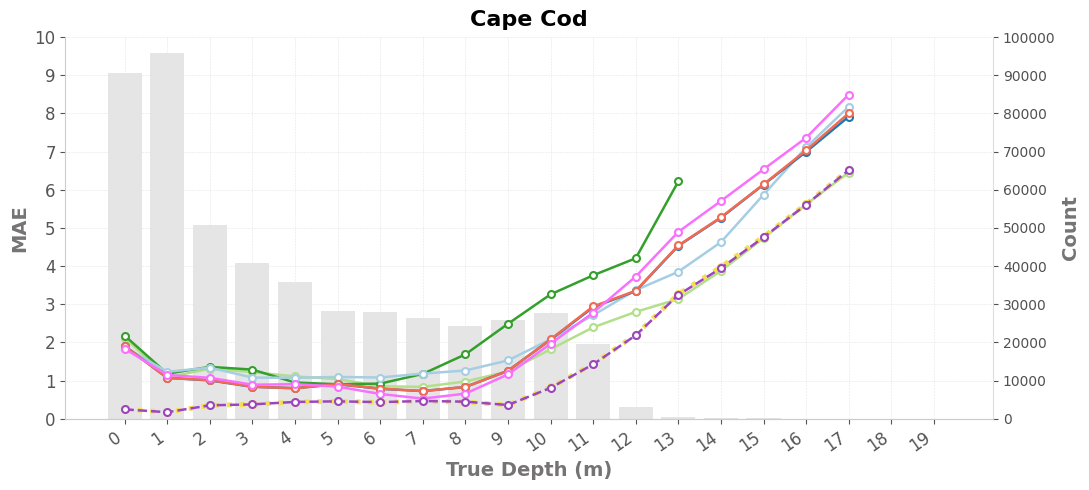

In [12]:
plot_depth_disaggregate(
    files,
    title=f"{site_full}",
    reference_line=None,
    extra_files={                                   # edit these to reflect site and method
        "Product Median":                              CC_XGBRF_Pmed,
        "Product Median (Maximum Outlier Removal 3σ)": CC_XGBRF_Pmed3o,
    },
    show_legend=False, # True to show legend, False to hide
    save_path=parent / f"{site_name}_{method_name}_depth_disaggregate_EDIT_NAME.png",
    dpi=300,
)